Exploratory data analysis (EDA) is a crucial component of data science which allows you to understand the basics of what your data looks like and what kinds of questions might be answered. For this task, we are going to clean, sanitise and explore our data. Using the automobile dataset, complete the steps outlined in this notebook by writing code in the cells.

In [ ]:
# Import libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
%matplotlib inline
sns.set_theme(style="whitegrid")
FIGURE_DIR = Path("report_figures")
FIGURE_DIR.mkdir(exist_ok=True)

In [2]:
# Load the automobiles dataset
automobiles_df = pd.read_csv("automobile.txt", na_values="?")
raw_shape = automobiles_df.shape
automobiles_df.head()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0


### Data Cleansing
#### Clean the data

Identify columns that are redundant or unnecessary. It is always easier to make your decisions based on data which is relevant and concise. Remove the following columns `['normalized-losses', 'symboling']` from the data set as they will not be used in the analysis.

In [3]:
# Remove redundant columns
automobiles_df = automobiles_df.drop(columns=["normalized-losses", "symboling"])
automobiles_df.head()

,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0
1,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0
2,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0
3,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,...,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0
4,audi,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,...,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0


#### Remove any duplicate rows

In [4]:
# Remove duplicate rows
rows_before_duplicates = len(automobiles_df)
automobiles_df = automobiles_df.drop_duplicates().copy()
duplicates_removed = rows_before_duplicates - len(automobiles_df)
print(f"Duplicate rows removed: {duplicates_removed}")
automobiles_df.shape

Duplicate rows removed: 0


(205, 24)

#### Remove rows with missing data

Some automobiles in the database have missing values which implies that their values have not been recorded or some information is missing. Discard such entries from the dataframe.

In [5]:
# Remove rows with missing data
rows_before_missing = len(automobiles_df)
automobiles_df = automobiles_df.dropna().copy()
missing_rows_removed = rows_before_missing - len(automobiles_df)
print(f"Rows removed because of missing values: {missing_rows_removed}")
automobiles_df.shape

Rows removed because of missing values: 12


(193, 24)

Change columns with numerical data column to an integer data type using numpy’s `int64` method.

In [6]:
# Convert numeric columns to suitable numeric data types.
# Continuous measurements remain float; count-like variables use NumPy int64.
float_columns = ["wheel-base", "length", "width", "height", "bore", "stroke", "compression-ratio"]
int_columns = ["curb-weight", "engine-size", "horsepower", "peak-rpm", "city-mpg", "highway-mpg", "price"]

for column in float_columns + int_columns:
    automobiles_df[column] = pd.to_numeric(automobiles_df[column], errors="raise")

automobiles_df[float_columns] = automobiles_df[float_columns].astype(float)
automobiles_df[int_columns] = automobiles_df[int_columns].astype(np.int64)
automobiles_df.dtypes

make                     str
fuel-type                str
aspiration               str
num-of-doors             str
body-style               str
drive-wheels             str
engine-location          str
wheel-base           float64
length               float64
width                float64
height               float64
curb-weight            int64
engine-type              str
num-of-cylinders         str
engine-size            int64
fuel-system              str
bore                 float64
stroke               float64
compression-ratio    float64
horsepower             int64
peak-rpm               int64
city-mpg               int64
highway-mpg            int64
price                  int64
dtype: object

### Finding Certain Categories
Locate all automobiles in the "hatchback" genre.

,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
2,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,...,152,mpfi,2.68,3.47,9.00,154,5000,19,26,16500
18,chevrolet,gas,std,two,hatchback,fwd,front,88.4,141.1,60.3,...,61,2bbl,2.91,3.03,9.50,48,5100,47,53,5151
19,chevrolet,gas,std,two,hatchback,fwd,front,94.5,155.9,63.6,...,90,2bbl,3.03,3.11,9.60,70,5400,38,43,6295
21,dodge,gas,std,two,hatchback,fwd,front,93.7,157.3,63.8,...,90,2bbl,2.97,3.23,9.41,68,5500,37,41,5572
22,dodge,gas,std,two,hatchback,fwd,front,93.7,157.3,63.8,...,90,2bbl,2.97,3.23,9.40,68,5500,31,38,6377


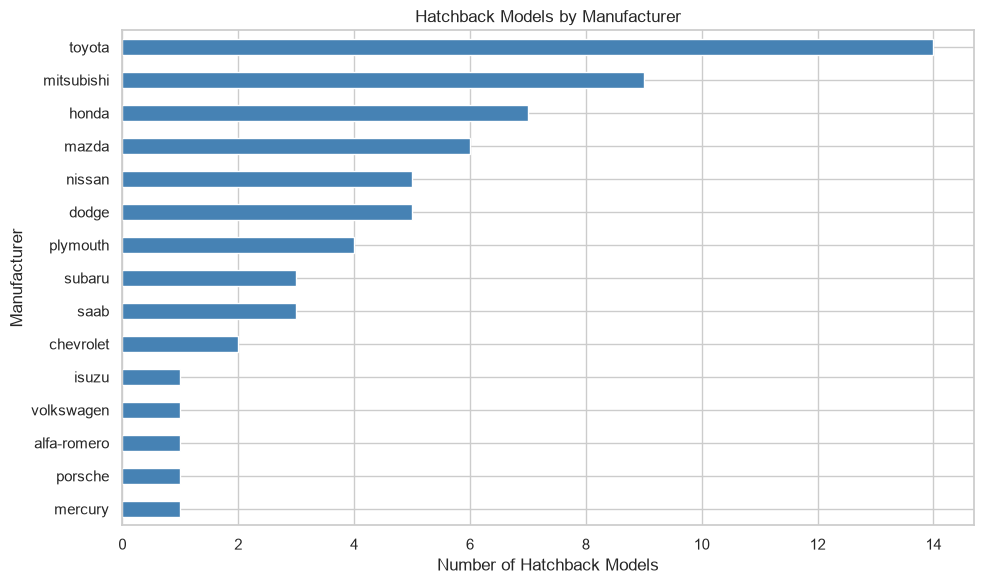

In [7]:
# Create a dataframe with all cars in the hatchback category
hatchback_cars = automobiles_df.loc[automobiles_df["body-style"].eq("hatchback")].copy()
display(hatchback_cars.head())

# Visualise the hatchback category by manufacturer.
fig, ax = plt.subplots(figsize=(10, 6))
hatchback_cars["make"].value_counts().sort_values().plot(kind="barh", ax=ax, color="steelblue")
ax.set_title("Hatchback Models by Manufacturer")
ax.set_xlabel("Number of Hatchback Models")
ax.set_ylabel("Manufacturer")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "01_hatchbacks.png", dpi=180, bbox_inches="tight")
plt.show()

### Now onto the exploration

#### Identify relationships between variables (features)

The main goal here is to identify and create relationships that can help you formulate ideas. We have defined questions to help you identify some relationships to explore.

#### Which are the 5 most expensive cars?

How do the most expensive and cheapest cars compare? Exploring the most expensive cars highlights if some moviecars are worth the money spent on them based on their fuel economy (mpg or miles per gallon)

,make,body-style,engine-size,city-mpg,highway-mpg,price
17,bmw,sedan,209,15,20,36880
128,porsche,convertible,194,17,25,37028
73,mercedes-benz,sedan,308,14,16,40960
16,bmw,sedan,209,16,22,41315
74,mercedes-benz,hardtop,304,14,16,45400


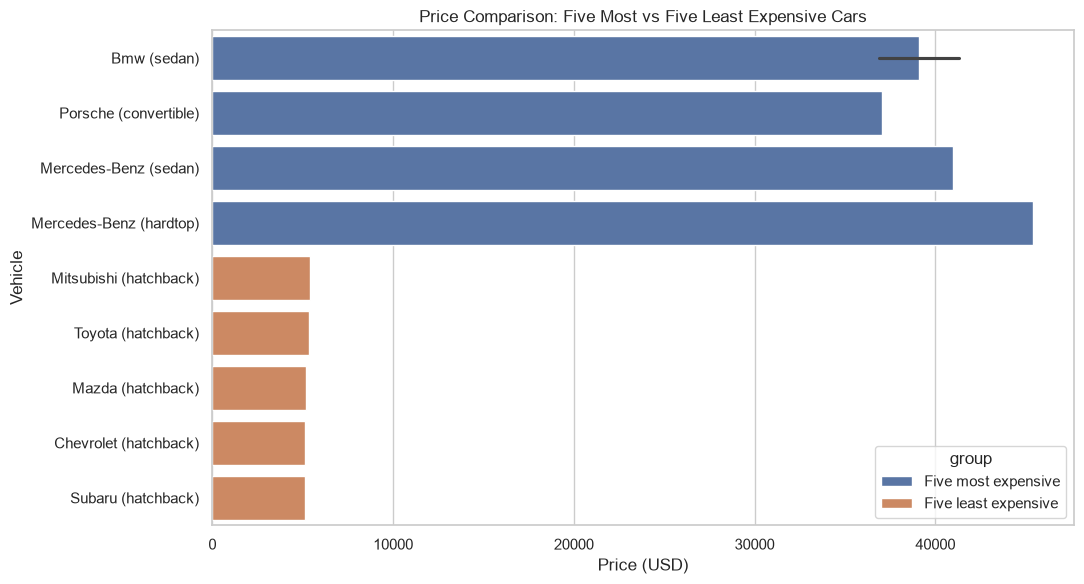

In [8]:
# Identify the 5 most expensive cars and compare them to the 5 cheapest.
most_expensive_cars = automobiles_df.nlargest(5, "price").sort_values("price")
least_expensive_cars = automobiles_df.nsmallest(5, "price").sort_values("price", ascending=False)
display(most_expensive_cars[["make", "body-style", "engine-size", "city-mpg", "highway-mpg", "price"]])

comparison = pd.concat([
    most_expensive_cars.assign(group="Five most expensive"),
    least_expensive_cars.assign(group="Five least expensive")
])
comparison["vehicle"] = comparison["make"].str.title() + " (" + comparison["body-style"] + ")"

fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(data=comparison, y="vehicle", x="price", hue="group", dodge=False, ax=ax)
ax.set_title("Price Comparison: Five Most vs Five Least Expensive Cars")
ax.set_xlabel("Price (USD)")
ax.set_ylabel("Vehicle")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "02_price_extremes.png", dpi=180, bbox_inches="tight")
plt.show()

#### Which manufacturer builds the most fuel efficient vehicles?

Compare the average mpg for each vehicle manufacture's vehicles and create a bar plot

Most fuel-efficient manufacturer by average city MPG: Chevrolet


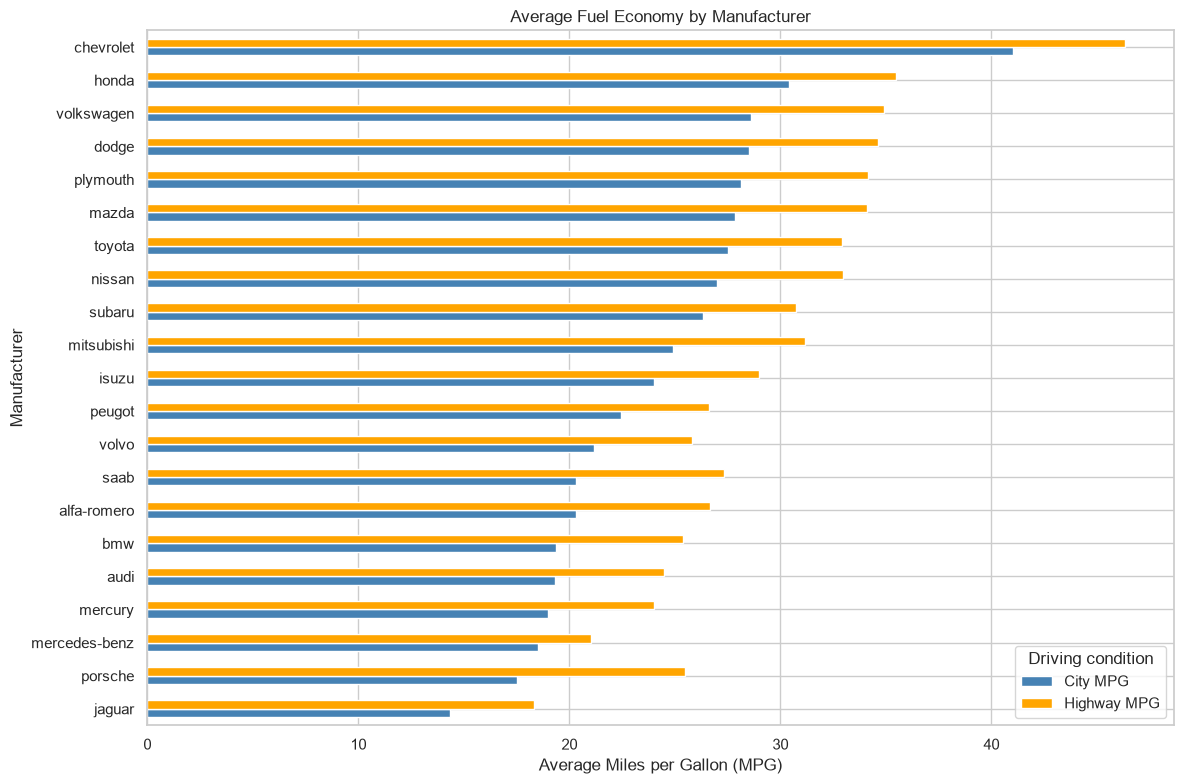

In [9]:
# Compare average city and highway MPG by manufacturer.
manufacturer_mpg = automobiles_df.groupby("make")[["city-mpg", "highway-mpg"]].mean().sort_values("city-mpg")
print("Most fuel-efficient manufacturer by average city MPG:", manufacturer_mpg.index[-1].title())

fig, ax = plt.subplots(figsize=(12, 8))
manufacturer_mpg.plot(kind="barh", ax=ax, color=["steelblue", "orange"])
ax.set_title("Average Fuel Economy by Manufacturer")
ax.set_xlabel("Average Miles per Gallon (MPG)")
ax.set_ylabel("Manufacturer")
ax.legend(["City MPG", "Highway MPG"], title="Driving condition")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "03_fuel_economy.png", dpi=180, bbox_inches="tight")
plt.show()

#### Which vehicles have the largest engine capacity.
Sort the dataframe based on the engine-size column.

,make,body-style,engine-size,horsepower,price
0,jaguar,sedan,326,262,36000
1,mercedes-benz,sedan,308,184,40960
2,mercedes-benz,hardtop,304,184,45400
3,jaguar,sedan,258,176,32250
4,jaguar,sedan,258,176,35550
5,mercedes-benz,sedan,234,155,34184
6,mercedes-benz,convertible,234,155,35056
7,bmw,sedan,209,182,30760
8,bmw,sedan,209,182,41315
9,bmw,sedan,209,182,36880


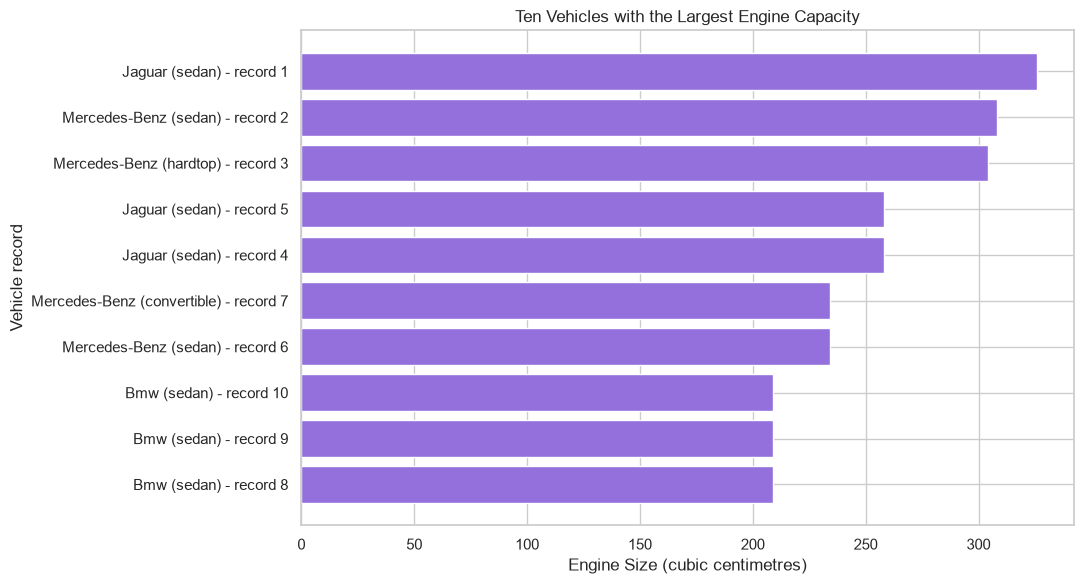

In [10]:
# Sort the dataframe by engine size and visualise the ten largest engine records.
# reset_index and a record number ensure all 10 selected vehicles have unique labels.
largest_engine_cars = automobiles_df.nlargest(10, "engine-size").reset_index(drop=True).copy()
largest_engine_cars["vehicle"] = (
    largest_engine_cars["make"].str.title()
    + " (" + largest_engine_cars["body-style"] + ")"
    + " - record " + (largest_engine_cars.index + 1).astype(str)
)
display(largest_engine_cars[["make", "body-style", "engine-size", "horsepower", "price"]])

fig, ax = plt.subplots(figsize=(11, 6))
ordered = largest_engine_cars.sort_values("engine-size")
ax.barh(ordered["vehicle"], ordered["engine-size"], color="mediumpurple")
ax.set_title("Ten Vehicles with the Largest Engine Capacity")
ax.set_xlabel("Engine Size (cubic centimetres)")
ax.set_ylabel("Vehicle record")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "04_engine_capacity.png", dpi=180, bbox_inches="tight")
plt.show()

#### Which vehicle manufacturer has the most car models in the dataset

Manufacturer with the most car models: Toyota


make
toyota        32
nissan        18
honda         13
mitsubishi    13
mazda         12
subaru        12
volkswagen    12
peugot        11
volvo         11
bmw            8
Name: count, dtype: int64

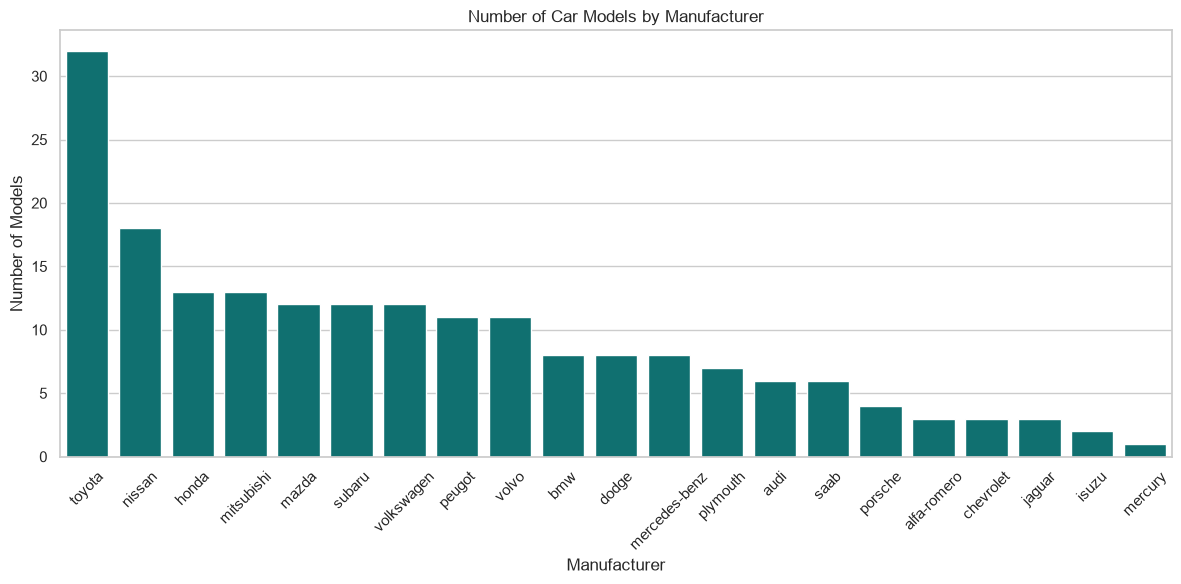

In [11]:
# Count car models by manufacturer and visualise the result.
manufacturer_counts = automobiles_df["make"].value_counts()
print("Manufacturer with the most car models:", manufacturer_counts.index[0].title())
display(manufacturer_counts.head(10))

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(x=manufacturer_counts.index, y=manufacturer_counts.values, color="teal", ax=ax)
ax.set_title("Number of Car Models by Manufacturer")
ax.set_xlabel("Manufacturer")
ax.set_ylabel("Number of Models")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "05_model_counts.png", dpi=180, bbox_inches="tight")
plt.show()

#### Additional relationship used in the EDA report

The following visualisation makes the report's Price vs Engine Size chart reproducible in this notebook.

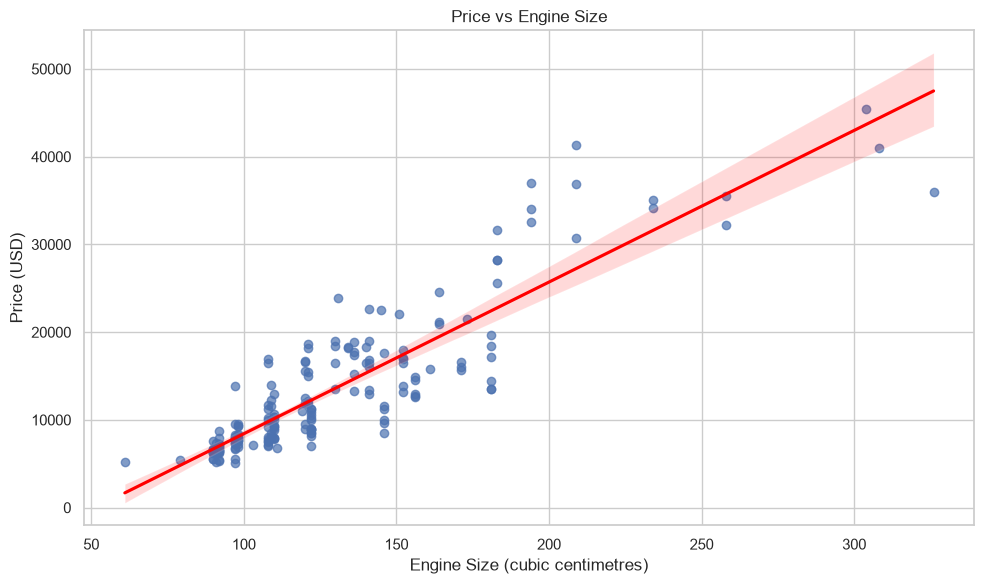

Pearson correlation between engine size and price: 0.89


In [12]:
# Visualisation: Price versus engine size
fig, ax = plt.subplots(figsize=(10, 6))
sns.regplot(data=automobiles_df, x="engine-size", y="price", scatter_kws={"alpha": 0.7}, line_kws={"color": "red"}, ax=ax)
ax.set_title("Price vs Engine Size")
ax.set_xlabel("Engine Size (cubic centimetres)")
ax.set_ylabel("Price (USD)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "06_price_engine_size.png", dpi=180, bbox_inches="tight")
plt.show()

correlation = automobiles_df[["engine-size", "price"]].corr().iloc[0, 1]
print(f"Pearson correlation between engine size and price: {correlation:.2f}")